<a href="https://colab.research.google.com/github/scudilio/AI---Deep-Learning/blob/main/Aula%203/%20MBA_DL_Aula_3_02_aplicacao1_sentimento_reviews.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 3 | Aplicação 1: classificar o sentimento de 30 mil reviews

**MBA FIAP | Deep Learning e Redes Neurais Modernas | Profa. Juliana Scudilio**

**Problema de negócio.** Um e-commerce recebe milhares de avaliações por dia. Quais são reclamações que precisam de resposta hoje? Classificar o sentimento automaticamente é o primeiro filtro de qualquer operação de SAC, reviews ou redes sociais.

**Dados.** 30.000 reviews de produtos em português (B2W-Reviews01, Americanas.com, 2018), metade negativos (1 ou 2 estrelas) e metade positivos (4 ou 5 estrelas).

**Duas abordagens, uma pergunta.** Primeiro um **baseline** clássico (TF-IDF + regressão logística): segundos para treinar, totalmente explicável. Depois uma rede **LSTM** com camada de embedding, que lê o texto palavra a palavra. A pergunta da aula: *a rede paga o que custa?*

**Roteiro (50 min).** 1. Dados → 2. Divisão → 3. Baseline → 4. Interpretar → 5. LSTM → 6. Comparar → 7. Erros → 8. MLflow.

In [12]:
import os, re, time, tempfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn

torch.manual_seed(42); np.random.seed(42)
cands = ["reviews_b2w_subset.csv", "../data/reviews_b2w_subset.csv", "data/reviews_b2w_subset.csv"]
caminho = next((c for c in cands if os.path.exists(c)), None)
if caminho is None:                                   # no Colab: abre o seletor de arquivos
    from google.colab import files
    print("Envie o arquivo reviews_b2w_subset.csv:")
    caminho = list(files.upload())[0]
df = pd.read_csv(caminho)
df["y"] = (df["sentimento"] == "positivo").astype(int)
print(df.shape, "| PyTorch", torch.__version__, "| GPU?", torch.cuda.is_available())

(30000, 9) | PyTorch 2.14.1+cpu | GPU? False


## 1. Conhecer os dados

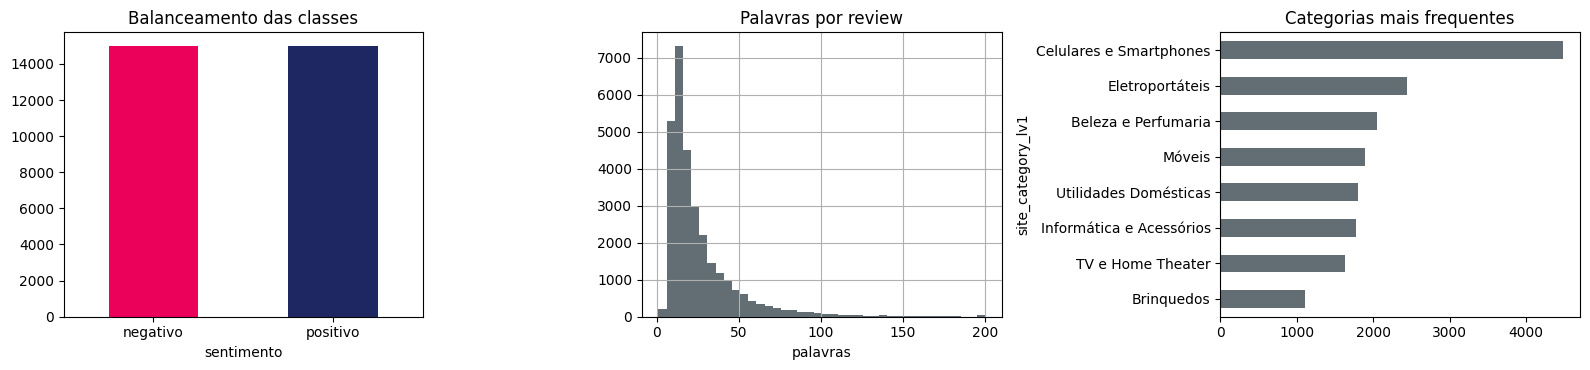

,review_text,overall_rating,sentimento
10747,"Eu comprei pelo custo beneficio. Mas ao utilizar, o produto me surpreendeu bastante. Extremamente confortável, e com uma resposta e precisão incr...",5,positivo
12573,Só fiquem cientes que quem entrega é o correios. Então atrasar é meio que normal pra eles. Salve pra Curitiba.,5,positivo
29676,Cartucho entregue com validade de dois meses (06/2018)! Gostaria que trocassem por um válido por no mínimo um ano. Já apresentou defeito na primei...,1,negativo
8856,A Americana está de parabéns. Entrega muito rapido. Gostei muito.,5,positivo


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
df["sentimento"].value_counts().plot.bar(ax=axes[0], color=["#EB005A", "#1E2761"], rot=0); axes[0].set_title("Balanceamento das classes")
df["review_text"].str.split().str.len().clip(upper=200).hist(bins=40, ax=axes[1], color="#626E73"); axes[1].set_title("Palavras por review"); axes[1].set_xlabel("palavras")
df["site_category_lv1"].value_counts().head(8).plot.barh(ax=axes[2], color="#626E73"); axes[2].set_title("Categorias mais frequentes"); axes[2].invert_yaxis()
plt.tight_layout(); plt.show()
pd.set_option("display.max_colwidth", 150)
df[["review_text", "overall_rating", "sentimento"]].sample(4, random_state=1)

## 2. Dividir: treino, validação e teste

A mesma regra da aula 1. O teste (3.000 reviews) fica intocado até o fim.

In [14]:
from sklearn.model_selection import train_test_split
tr, temp = train_test_split(df, test_size=6000, stratify=df["y"], random_state=0)
val, te = train_test_split(temp, test_size=3000, stratify=temp["y"], random_state=0)
print("treino", len(tr), "| validação", len(val), "| teste", len(te))

treino 24000 | validação 3000 | teste 3000


## 3. Baseline: TF-IDF + regressão logística

O modelo mais simples que resolve o problema. Se a rede neural não bater isso, ela não se paga.

In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

t0 = time.time()




Cria o vetorizador, ainda sem ver texto nenhum. Os três parâmetros são decisões:

ngram_range=(1, 2): as colunas são palavras e pares de palavras consecutivas. É isso que cria a coluna “não gostei” e recupera parte da negação, que a sacola simples perde.
min_df=3: um termo só vira coluna se aparecer em pelo menos 3 reviews. Corta erros de digitação únicos e pares raros; sem isso o vocabulário passaria de 300 mil colunas.
sublinear_tf=True: em vez de contar a frequência bruta, usa 1 + log(frequência). Um review que repete “péssimo” cinco vezes não pesa cinco vezes mais que um que diz uma vez; pesa cerca de 2,6 vezes.





In [16]:
tfidf = TfidfVectorizer(min_df=3, ngram_range=(1, 2), sublinear_tf=True)    # palavras e pares de palavras ("não gostei")

### ATENCAO!

A linha mais importante do trecho, e a que mais gente erra. fit_transform no treino faz duas coisas: aprende o vocabulário e a raridade de cada termo (o IDF) só com os 24 mil reviews de treino, e depois converte. Validação e teste usam apenas transform: são convertidos com o vocabulário e o IDF já aprendidos.




In [17]:
Xtr = tfidf.fit_transform(tr["review_text"]);
Xval = tfidf.transform(val["review_text"]);
Xte = tfidf.transform(te["review_text"])


In [18]:
base = LogisticRegression(max_iter=1000, C=2.0).fit(Xtr, tr["y"])
tempo_base = time.time() - t0

pred_val = base.predict(Xval)
print(f"Vocabulário (palavras e pares): {Xtr.shape[1]:,} | tempo de treino: {tempo_base:.1f} s")
print(f"Validação: acurácia {accuracy_score(val['y'], pred_val):.1%} | F1 {f1_score(val['y'], pred_val):.3f}")

Vocabulário (palavras e pares): 35,271 | tempo de treino: 2.1 s
Validação: acurácia 94.2% | F1 0.941


⏱ **Checkpoint 1:** acurácia de validação acima de 85%? Treinou em poucos segundos?

## 4. Interpretar: o que o modelo aprendeu

Cada palavra tem um peso. Positivo empurra para "positivo", negativo para "negativo". Isso é o que um gerente consegue auditar.

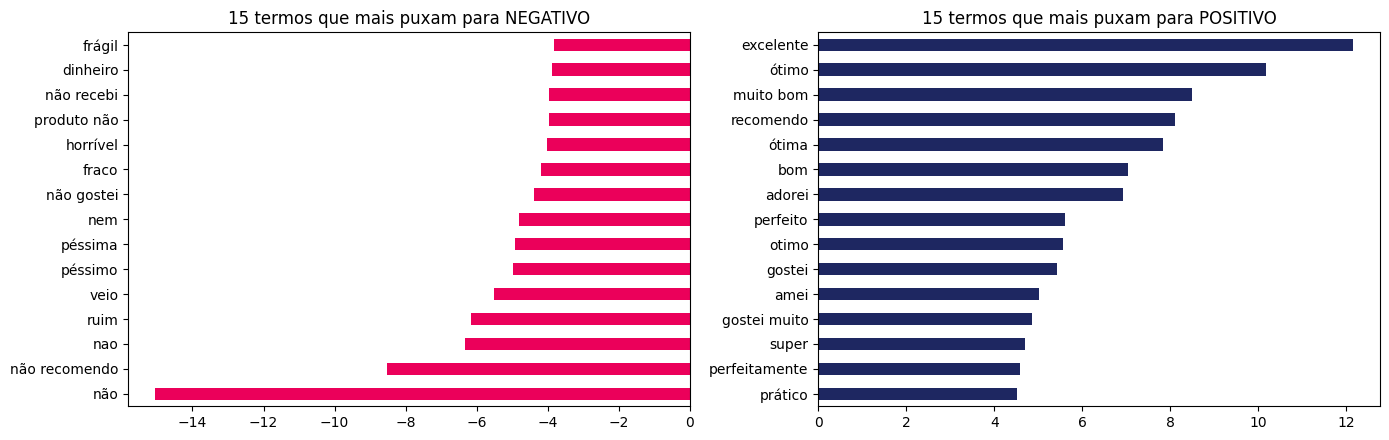

In [19]:
pesos = pd.Series(base.coef_[0], index=tfidf.get_feature_names_out())
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
pesos.sort_values().head(15).plot.barh(ax=axes[0], color="#EB005A"); axes[0].set_title("15 termos que mais puxam para NEGATIVO")
pesos.sort_values().tail(15).plot.barh(ax=axes[1], color="#1E2761"); axes[1].set_title("15 termos que mais puxam para POSITIVO")
plt.tight_layout(); plt.show()

In [20]:
def classificar_base(frases):
    p = base.predict_proba(tfidf.transform(frases))[:, 1]
    for f, pi in zip(frases, p): print(f"{pi:5.0%} positivo | {f}")

classificar_base(["Produto excelente, chegou antes do prazo.",
                  "Não gostei, veio com defeito e o SAC não resolve.",
                  "Chegou rápido, mas parou de funcionar em uma semana.",
                  "Não é ruim.",
                  "Esperava mais pelo preço."])

 100% positivo | Produto excelente, chegou antes do prazo.
   0% positivo | Não gostei, veio com defeito e o SAC não resolve.
  20% positivo | Chegou rápido, mas parou de funcionar em uma semana.
   0% positivo | Não é ruim.
  15% positivo | Esperava mais pelo preço.


Troque as frases pelas da turma. Repare onde o baseline tropeça: negação ("não é ruim"), contraste ("mas") e ironia. A sacola de palavras não lê ordem.

## 5. Uma rede que lê na ordem: LSTM

A LSTM processa o texto palavra a palavra, carregando um "estado" que resume o que já leu. Em tese, consegue aprender que "não" inverte o que vem depois.

Passos: 1) vocabulário das 10.000 palavras mais comuns; 2) cada review vira uma sequência de até 60 números (índices); 3) camada de **embedding** (cada índice vira um vetor de 64 números, aprendido no treino); 4) LSTM; 5) saída.

In [21]:
from collections import Counter
tok = lambda s: re.findall(r"[a-záàâãéêíóôõúç0-9]+", str(s).lower())
MAXLEN, VOCAB = 60, 10000
cont = Counter(w for t in tr["review_text"] for w in tok(t))
vocab = ["<pad>", "<unk>"] + [w for w, _ in cont.most_common(VOCAB - 2)]
idx = {w: i for i, w in enumerate(vocab)}

def codificar(textos):
    M = np.zeros((len(textos), MAXLEN), dtype=np.int64)
    for i, t in enumerate(textos):
        ids = [idx.get(w, 1) for w in tok(t)][:MAXLEN]
        M[i, MAXLEN - len(ids):] = ids       # preenche com 0 (<pad>) à ESQUERDA: as últimas palavras lidas pela LSTM são as reais
    return torch.tensor(M)

Str, Sval, Ste = codificar(tr["review_text"]), codificar(val["review_text"]), codificar(te["review_text"])
ytr, yval, yte = (torch.tensor(d["y"].values) for d in (tr, val, te))
print("Exemplo codificado:", tr["review_text"].iloc[0][:80], "->", Str[0][:12].tolist(), "...")

Exemplo codificado: Produto atende às expectativas. Purificador de fácil instalação e de boa vazão. -> [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0] ...


In [22]:
class RedeLSTM(nn.Module):
    def __init__(self, n_vocab, dim=64, oculto=64):
        super().__init__()
        self.emb = nn.Embedding(n_vocab, dim, padding_idx=0)
        self.lstm = nn.LSTM(dim, oculto, batch_first=True)
        self.drop = nn.Dropout(0.3)
        self.saida = nn.Linear(oculto, 2)
    def forward(self, x):
        e = self.emb(x)                       # (lote, 60, 64)
        _, (h, _) = self.lstm(e)              # h: estado final após ler a sequência
        return self.saida(self.drop(h[-1]))

rede = RedeLSTM(len(vocab))
print(f"Parâmetros: {sum(p.numel() for p in rede.parameters()):,} (a camada de embedding tem {len(vocab)*64:,})")

Parâmetros: 673,410 (a camada de embedding tem 640,000)


In [23]:
EPOCAS, LOTE = 5, 128
perda_fn = nn.CrossEntropyLoss(); otim = torch.optim.Adam(rede.parameters(), lr=2e-3)

def avaliar(modelo, S, y):
    modelo.eval(); preds = []
    with torch.no_grad():
        for i in range(0, len(S), 1000): preds.append(modelo(S[i:i+1000]).argmax(1))
    p = torch.cat(preds); return (p == y).float().mean().item(), p.numpy()

hist = {"acc_tr": [], "acc_val": []}; t0 = time.time(); melhor = (0, None)
for ep in range(1, EPOCAS + 1):
    rede.train(); perm = torch.randperm(len(Str)); t1 = time.time()
    for i in range(0, len(Str), LOTE):
        b = perm[i:i+LOTE]; otim.zero_grad(); perda = perda_fn(rede(Str[b]), ytr[b]); perda.backward(); otim.step()
    a_tr, _ = avaliar(rede, Str[:5000], ytr[:5000]); a_val, _ = avaliar(rede, Sval, yval)
    hist["acc_tr"].append(a_tr); hist["acc_val"].append(a_val)
    if a_val > melhor[0]: melhor = (a_val, {k: v.clone() for k, v in rede.state_dict().items()})
    print(f"época {ep} | acurácia treino {a_tr:.1%} | validação {a_val:.1%} | {time.time()-t1:.0f}s")
tempo_lstm = time.time() - t0
rede.load_state_dict(melhor[1]); print(f"Melhor validação: {melhor[0]:.1%} | tempo total {tempo_lstm:.0f}s")

época 1 | acurácia treino 91.7% | validação 90.3% | 22s
época 2 | acurácia treino 94.5% | validação 93.0% | 15s
época 3 | acurácia treino 96.5% | validação 93.8% | 16s
época 4 | acurácia treino 97.2% | validação 93.4% | 16s
época 5 | acurácia treino 98.0% | validação 93.7% | 15s
Melhor validação: 93.8% | tempo total 83s


⏱ **Checkpoint 2:** as 5 épocas terminaram? Anote o tempo e compare com o baseline.

## 6. Comparar no teste: a rede paga o que custa?

In [24]:
t0 = time.time(); pb = base.predict(Xte); inf_base = (time.time() - t0) / len(te) * 1000
t0 = time.time(); acc_l, pl = avaliar(rede, Ste, yte); inf_lstm = (time.time() - t0) / len(te) * 1000

comp = pd.DataFrame({
    "acurácia (teste)": [accuracy_score(te["y"], pb), acc_l],
    "F1 (teste)": [f1_score(te["y"], pb), f1_score(te["y"], pl)],
    "tempo de treino (s)": [tempo_base, tempo_lstm],
    "inferência (ms por review)": [inf_base, inf_lstm],
    "explicável?": ["sim: um peso por termo", "parcialmente"],
}, index=["TF-IDF + regressão logística", "LSTM com embedding"])
comp.round(3)

,acurácia (teste),F1 (teste),tempo de treino (s),inferência (ms por review),explicável?
TF-IDF + regressão logística,0.939,0.938,2.145,0.001,sim: um peso por termo
LSTM com embedding,0.926,0.925,83.462,0.199,parcialmente


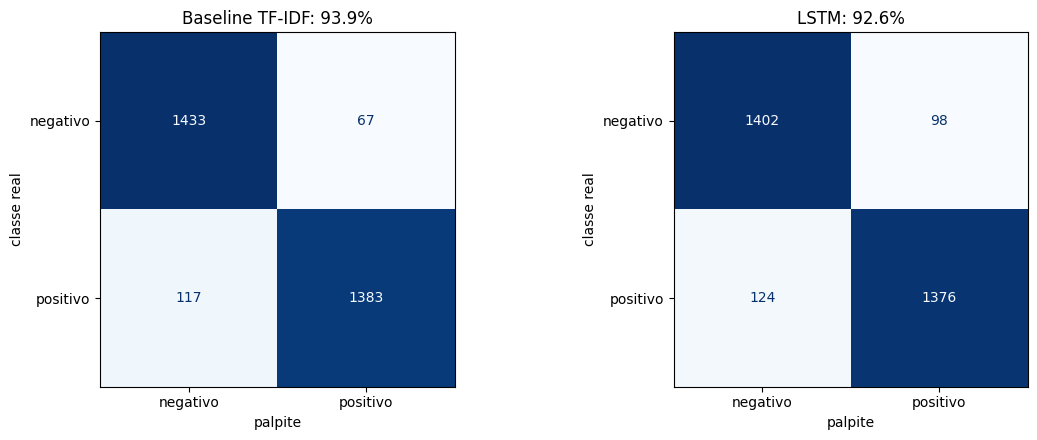

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, p, nome in zip(axes, [pb, pl], ["Baseline TF-IDF", "LSTM"]):
    ConfusionMatrixDisplay(confusion_matrix(te["y"], p), display_labels=["negativo", "positivo"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{nome}: {accuracy_score(te['y'], p):.1%}"); ax.set_xlabel("palpite"); ax.set_ylabel("classe real")
plt.tight_layout(); plt.show()

**Leitura de negócio.** Em reviews curtos e diretos, o baseline chega perto da rede com uma fração do custo e com pesos auditáveis. A rede ganha quando a ordem importa (negação, contraste), em textos longos, ou quando há muito mais dado. **Mais complexo não é melhor por padrão: é melhor quando o dado exige.**

## 7. Onde cada modelo erra

In [26]:
te2 = te.copy(); te2["baseline"] = pb; te2["lstm"] = pl
so_lstm_acerta = te2[(te2.baseline != te2.y) & (te2.lstm == te2.y)]
so_base_acerta = te2[(te2.baseline == te2.y) & (te2.lstm != te2.y)]
print(f"Só a LSTM acerta: {len(so_lstm_acerta)} reviews | só o baseline acerta: {len(so_base_acerta)} | os dois erram: {((te2.baseline != te2.y) & (te2.lstm != te2.y)).sum()}")
print("\nExemplos em que só a LSTM acerta (ordem e negação costumam estar aqui):")
for t, y in so_lstm_acerta[["review_text", "sentimento"]].head(4).values: print(f" [{y}] {t[:160]}")
print("\nExemplos em que os dois erram (ambíguos, irônicos ou rotulados de forma estranha):")
for t, y in te2[(te2.baseline != te2.y) & (te2.lstm != te2.y)][["review_text", "sentimento"]].head(4).values: print(f" [{y}] {t[:160]}")

Só a LSTM acerta: 49 reviews | só o baseline acerta: 87 | os dois erram: 135

Exemplos em que só a LSTM acerta (ordem e negação costumam estar aqui):
 [positivo] Espetacular, feita de Adamantium com cabo de Kriptonita, única arma capaz de combater o Superman e o Wolverine juntos. A lenda diz que foi usada para forjar as 
 [negativo] Estou com medo de n VM certo o produto.. me ajudem
 [negativo] Pela foto o produto parece resistente  e de qualidade ... mais é totalmente ao contrario
 [positivo] Recomendo e barato e vem com todos os gears colection toppppp mas eles dam mole de não falar que é a colection edition

Exemplos em que os dois erram (ambíguos, irônicos ou rotulados de forma estranha):
 [positivo] Só eu consigo tirar o chip. A bateria não sai. Carrega rápido.
 [negativo] É um televisor simples e funciona muito bem: imagem nítida, aparelho de fácil configuração. O único ponto negativo é o áudio, que é extremamente baixo. Como a T
 [positivo] Maravilhoso, não há como não gostar, n

In [27]:
def classificar_lstm(frases):
    rede.eval()
    with torch.no_grad(): p = torch.softmax(rede(codificar(frases)), 1)[:, 1].numpy()
    for f, pi in zip(frases, p): print(f"{pi:5.0%} positivo | {f}")

frases_turma = ["Produto excelente, chegou antes do prazo.", "Não gostei, veio com defeito e o SAC não resolve.",
                "Chegou rápido, mas parou de funcionar em uma semana.", "Não é ruim.", "Esperava mais pelo preço."]
print("Baseline:"); classificar_base(frases_turma)
print("\nLSTM:"); classificar_lstm(frases_turma)

Baseline:
 100% positivo | Produto excelente, chegou antes do prazo.
   0% positivo | Não gostei, veio com defeito e o SAC não resolve.
  20% positivo | Chegou rápido, mas parou de funcionar em uma semana.
   0% positivo | Não é ruim.
  15% positivo | Esperava mais pelo preço.

LSTM:
 100% positivo | Produto excelente, chegou antes do prazo.
   1% positivo | Não gostei, veio com defeito e o SAC não resolve.
  13% positivo | Chegou rápido, mas parou de funcionar em uma semana.
   2% positivo | Não é ruim.
  59% positivo | Esperava mais pelo preço.


## 8. Registrar no MLflow

In [28]:
try:
    import mlflow
    with mlflow.start_run(run_name="sentimento_baseline_tfidf"):
        mlflow.log_params({"modelo": "tfidf+logreg", "ngram": "1-2", "min_df": 3, "n_treino": len(tr)})
        mlflow.log_metrics({"acc_teste": accuracy_score(te["y"], pb), "f1_teste": f1_score(te["y"], pb), "tempo_treino_s": tempo_base})
    with mlflow.start_run(run_name="sentimento_lstm"):
        mlflow.log_params({"modelo": "lstm", "vocab": VOCAB, "maxlen": MAXLEN, "epocas": EPOCAS, "n_treino": len(tr)})
        mlflow.log_metrics({"acc_teste": acc_l, "f1_teste": f1_score(te["y"], pl), "tempo_treino_s": tempo_lstm})
        caminho_pesos = os.path.join(tempfile.gettempdir(), "lstm_sentimento.pt"); torch.save(rede.state_dict(), caminho_pesos); mlflow.log_artifact(caminho_pesos)
    print("Dois runs registrados. Veja em Experiments.")
except Exception as e:
    print("MLflow indisponível, seguindo sem registro:", e)

MLflow indisponível, seguindo sem registro: No module named 'mlflow'


## Para discutir

1. Com esses números, qual modelo você colocaria em produção amanhã? O que mudaria sua resposta?
2. O rótulo veio das estrelas. Que vieses isso traz? (3 estrelas foram descartadas; "recomendaria a um amigo" é outro rótulo possível.)
3. O baseline acerta "não gostei" porque viu o par de palavras no treino. Que frases do seu negócio a sacola de palavras não entenderia nunca?

**Próximo notebook:** sair do "positivo ou negativo" e descobrir **do que** os clientes reclamam, sem ler 15 mil reviews.